# What problem is the brain solving?

A model of behavior has to say what the behavior is *for*. Before asking how neurons estimate a
duration, we need to know what counts as a good estimate. Reporting the most likely value is one
answer. Reporting the average is another. They are not the same, and the data can tell them apart
only under some designs.

This unit has two parts.

**Part I · Foundations** builds the tools: probability on a grid, Bayes' rule, expected utility,
loss functions, the cost of exact inference, and resource limits. Every formula comes with its
code line and the shape of the array it produces.

**Part II · Case study** uses those tools on one timing question, in six stages:

| stage | question |
|---|---|
| 1. Cognitive phenomenon | What needs explaining? |
| 2. Behavioral experiment | How do we make it measurable? |
| 3. Empirical signature | What pattern in the data is the phenomenon? |
| 4. Computational model | What computation produces it, and can we identify it? |
| 5. Neural implementation | Could neurons carry it out? |
| 6. Prediction and failure | Which result would prove the model wrong? |

All data here are simulated from models whose parameters we set. That way every analysis can be
checked against the truth.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import minimize
from scipy.stats import norm

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
rng = np.random.default_rng(0)

# Part I · Foundations

## 1. Three questions about one behavior

Marr (1982) split the explanation of any information processing system into three questions. They
are easiest to see on a concrete task. A participant sees a flash lasting $s$ seconds and then holds
a key for the same time.

| level | the question | for duration reproduction |
|---|---|---|
| computational | What is being computed, and why is it the right thing? | Choose a key press that keeps the expected error small, given what is known about $s$. |
| algorithmic | Which representation and which steps? | Combine a noisy measurement with knowledge of the usual durations, then read out one number. |
| implementational | Which physical substrate? | Duration tuned neurons, an integrator, a motor command. |

The levels constrain each other but do not determine each other. Many algorithms solve one
computational problem, and many circuits run one algorithm. This unit stays mostly at the first
level. Its point is that the computational level is *testable*: different goals predict different
behavior.

## 2. Probability on a grid

We represent every belief as a vector of probabilities over a grid of possible values. Integrals
become sums, and every step is a line of NumPy.

The symbols, with what they mean in the task:

| symbol | meaning | array | shape |
|---|---|---|---|
| $s$ | the true duration on a trial | `s_grid` | (K,) |
| $m$ | the noisy internal measurement of that duration | `m_grid` | (M,) |
| $p(s)$ | the prior: how often each duration occurs in the experiment | `prior` | (K,) |
| $p(m \mid s)$ | the likelihood: how measurements scatter around a given duration | `lik` | (K, M) |

For timing, measurement noise grows with the duration (Gibbon, 1977). A convenient way to get that
is Gaussian noise on a log scale:

$$\log m = \log s + \varepsilon, \qquad \varepsilon \sim \mathcal N(0, \sigma_w^2).$$

Here $\sigma_w$ is the Weber fraction: the size of the noise relative to the duration.

In [2]:
K, M = 241, 200
s_grid = np.linspace(0.2, 2.2, K)                       # (K,) candidate durations, s
m_grid = np.exp(np.linspace(np.log(0.15), np.log(3.5), M))  # (M,) possible measurements, m
sigma_w = 0.15                                          # Weber fraction

prior = ((s_grid >= 0.4) & (s_grid <= 1.6)).astype(float)
prior /= prior.sum()                                    # (K,) uniform on 0.4 to 1.6 s

# p(m | s): one row per duration, one column per measurement
lik = norm.pdf(np.log(m_grid)[None, :], np.log(s_grid)[:, None], sigma_w)
lik /= lik.sum(axis=1, keepdims=True)                   # (K, M), each row sums to 1

print("prior", prior.shape, " likelihood", lik.shape)
print("rows of p(m|s) sum to", lik.sum(axis=1)[:3].round(6))

prior (241,)  likelihood (241, 200)
rows of p(m|s) sum to [1. 1. 1.]


Three rules turn these pieces into a belief about $s$ after seeing $m$.

| rule | formula | code | shape |
|---|---|---|---|
| joint | $p(s, m) = p(m \mid s)\,p(s)$ | `joint = lik * prior[:, None]` | (K, M) |
| marginal | $p(m) = \sum_s p(s, m)$ | `p_m = joint.sum(axis=0)` | (M,) |
| posterior | $p(s \mid m) = p(s, m) / p(m)$ | `post = joint / p_m` | (K, M) |

The last line is Bayes' rule. Each column of `post` is the belief about the duration after one
particular measurement.

joint sums to 1.0
posterior columns sum to [1. 1. 1.]


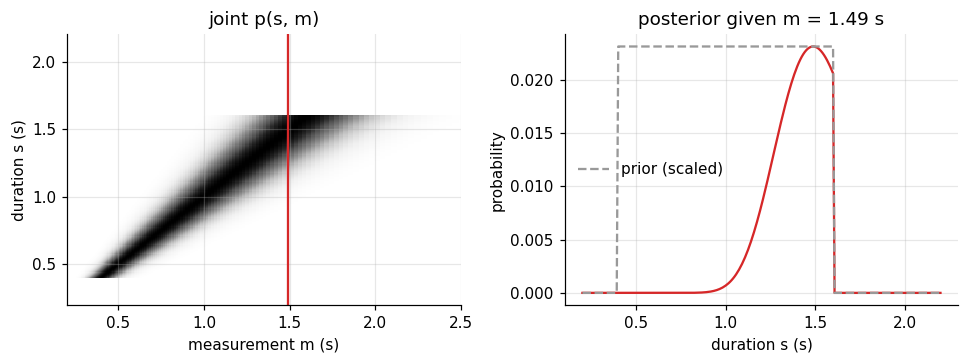

In [3]:
joint = lik * prior[:, None]          # (K, M)  p(s, m)
p_m = joint.sum(axis=0)               # (M,)    p(m), how often each measurement occurs
post = joint / p_m                    # (K, M)  p(s | m), one column per measurement

print("joint sums to", joint.sum().round(6))
print("posterior columns sum to", post.sum(axis=0)[[50, 100, 150]].round(6))

j = np.argmin(np.abs(m_grid - 1.5))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].pcolormesh(m_grid, s_grid, joint, shading="auto", cmap="Greys")
axes[0].axvline(m_grid[j], color="C3", lw=1.5)
axes[0].set(xlabel="measurement m (s)", ylabel="duration s (s)", title="joint p(s, m)", xlim=(0.2, 2.5))
axes[1].plot(s_grid, post[:, j], color="C3")
axes[1].plot(s_grid, prior / prior.max() * post[:, j].max(), color="0.6", ls="--", label="prior (scaled)")
axes[1].set(xlabel="duration s (s)", ylabel="probability", title=f"posterior given m = {m_grid[j]:.2f} s")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

The red column in the joint distribution, renormalized, is the posterior on the right. Two things
shape it. Log noise makes beliefs wider for longer durations. The prior ends at 1.6 s and cuts the
belief off sharply on the right, so the belief is lopsided: a steep wall on one side, a slope on
the other. Both features will matter.

## 3. Decisions: states, signals, actions, utility

A belief is not yet a behavior. Bayesian decision theory (Wald, 1950) adds three ingredients.

| symbol | meaning in the task | array | shape |
|---|---|---|---|
| $a$ | the action: how long the key is held | `a_grid` | (A,) |
| $\pi(a \mid m)$ | the policy: which action to take after measurement $m$ | `policy` | (M, A) |
| $u(s, a)$ | the utility: how good action $a$ is when the duration was $s$ | `util` | (K, A) |

The expected utility of an action, given a measurement, averages the utility over the posterior:

$$\bar u(a \mid m) = \sum_s p(s \mid m)\, u(s, a).$$

In code this is one matrix product, `EU = post.T @ util`, with shape (M, A). The best policy picks,
for each measurement, the action with the largest expected utility.

We start with the utility most experiments imply when they give points for accuracy: minus the
squared error, $u(s, a) = -(a - s)^2$.

In [4]:
a_grid = s_grid.copy()                                  # (A,) possible key presses, A = K here
util = -(a_grid[None, :] - s_grid[:, None]) ** 2        # (K, A) utility u(s, a)

EU = post.T @ util                                      # (M, A) expected utility of each action
best_a = a_grid[EU.argmax(axis=1)]                      # (M,)   the optimal action per measurement
policy = np.zeros((M, K)); policy[np.arange(M), EU.argmax(axis=1)] = 1   # (M, A) deterministic policy

# Value of the whole policy: average over measurements, actions, and states
value = (p_m[:, None] * policy * EU).sum()
print(f"expected utility of the optimal policy: {value:.4f}  (mean squared error {-value:.4f} s^2)")

# Check by brute force: simulate trials and score them
n = 200_000
s_sim = rng.choice(s_grid, size=n, p=prior)
m_sim = s_sim * np.exp(rng.normal(0, sigma_w, n))
a_sim = np.interp(m_sim, m_grid, best_a)
print(f"simulated mean squared error:            {np.mean((a_sim - s_sim) ** 2):.4f} s^2")

expected utility of the optimal policy: -0.0169  (mean squared error 0.0169 s^2)
simulated mean squared error:            0.0169 s^2


The two numbers agree. The grid calculation and a simulation of 200,000 trials give the same
answer, so the formula means what we said it means.

## 4. The loss decides which point of the belief you report

Utility is often written as a loss, $L = -u$. A short calculation shows which action minimizes each
common loss. Set the derivative of the expected loss to zero:

| loss $L(a, s)$ | what it punishes | optimal action | code |
|---|---|---|---|
| $(a - s)^2$ | large errors much more than small ones | posterior **mean** | `post_j @ s_grid` |
| $\lvert a - s \rvert$ | all errors in proportion | posterior **median** | first `s` where `cdf >= 0.5` |
| $\mathbb 1[a \neq s]$ | any error at all, equally | posterior **mode** | `s_grid[post_j.argmax()]` |
| $c_\text{late}(a-s)$ if late, $c_\text{early}(s-a)$ if early | late and early errors differently | posterior **quantile** $q = \frac{c_\text{early}}{c_\text{early} + c_\text{late}}$ | first `s` where `cdf >= q` |

The last row needs one line of algebra. The expected loss is
$c_\text{late} \sum_{s<a} p(s\mid m)(a-s) + c_\text{early} \sum_{s>a} p(s\mid m)(s-a)$.
Its slope in $a$ is $c_\text{late}\,P(s<a) - c_\text{early}\,P(s>a)$. That slope is zero where
$P(s<a) = c_\text{early} / (c_\text{early} + c_\text{late})$. If being late costs three times as much
as being early, $q = 1/4$: you aim at the point below which only a quarter of your belief lies.
Pressing early is cheap, so you accept being early three times out of four.

Below we check each row numerically: brute force search over actions must land on the formula.

squared      brute force 1.400 s   formula 1.400 s
absolute     brute force 1.417 s   formula 1.417 s
all or none  brute force 1.492 s   formula 1.492 s
late x3      brute force 1.308 s   formula 1.308 s


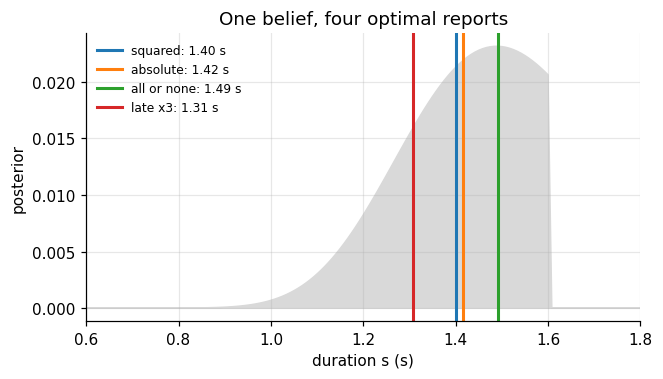

In [5]:
post_j = post[:, j]                                     # (K,) one skewed posterior
cdf = post_j.cumsum()                                   # (K,) P(s <= value)

losses = {
    "squared":   (a_grid[None, :] - s_grid[:, None]) ** 2,
    "absolute":  np.abs(a_grid[None, :] - s_grid[:, None]),
    "all or none": (np.abs(a_grid[None, :] - s_grid[:, None]) > 0.005).astype(float),
    "late x3":   np.where(a_grid[None, :] > s_grid[:, None],
                          3 * (a_grid[None, :] - s_grid[:, None]),
                          1 * (s_grid[:, None] - a_grid[None, :])),
}
formula = {
    "squared": post_j @ s_grid,
    "absolute": s_grid[np.searchsorted(cdf, 0.5)],
    "all or none": s_grid[post_j.argmax()],
    "late x3": s_grid[np.searchsorted(cdf, 0.25)],
}
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.fill_between(s_grid, post_j, color="0.85")
for (name, Lmat), col in zip(losses.items(), ["C0", "C1", "C2", "C3"]):
    exp_loss = post_j @ Lmat                            # (A,) expected loss of each action
    a_star = a_grid[exp_loss.argmin()]
    print(f"{name:12s} brute force {a_star:.3f} s   formula {formula[name]:.3f} s")
    ax.axvline(a_star, color=col, lw=2, label=f"{name}: {a_star:.2f} s")
ax.set(xlabel="duration s (s)", ylabel="posterior", xlim=(0.6, 1.8), title="One belief, four optimal reports")
ax.legend(frameon=False, fontsize=8)
plt.show()

One belief gives four different reports, spread over almost 0.2 s. The mode sits near the
measurement. The median and the mean are pulled away from the wall, and the quantile lies lower
still. Nothing about the perception changed. Only the goal changed. This is why a model of reproduction must state its
loss: a bias in the reports may come from the belief, from the loss, or from both.

## 5. Why exact inference gets expensive

The grid above has $K = 241$ values for one duration. Real inference problems involve many
variables at once. Suppose the brain wanted a joint belief about the durations of the last $N$
trials, which it would need if one trial's estimate depends on the others. The joint grid has
$K^N$ cells.

In [6]:
K_small = 50                                            # a coarse grid: 50 levels per duration
for N in [1, 2, 3, 5, 10, 20]:
    cells = float(K_small) ** N
    gigabytes = cells * 8 / 1e9
    print(f"N = {N:2d} trials: {cells:.1e} cells, {gigabytes:.1e} GB as float64")

N =  1 trials: 5.0e+01 cells, 4.0e-07 GB as float64
N =  2 trials: 2.5e+03 cells, 2.0e-05 GB as float64
N =  3 trials: 1.2e+05 cells, 1.0e-03 GB as float64
N =  5 trials: 3.1e+08 cells, 2.5e+00 GB as float64
N = 10 trials: 9.8e+16 cells, 7.8e+08 GB as float64
N = 20 trials: 9.5e+33 cells, 7.6e+25 GB as float64


Ten trials on a coarse grid already need more memory than exists. The difficulty is the
normalizer $p(m) = \sum_s p(m \mid s)p(s)$: it sums over every combination. Brains, and our models
of them, must therefore approximate. Later units cover the two main families, sampling and
variational methods. The design principles are the same everywhere: break the problem into parts,
reuse computation, sample instead of enumerating, and follow gradients.

## 6. Why Bayes, and what limits it

Two classical results explain why decision theory leans on probability.

- **Coherence.** If degrees of belief violate the rules of probability, a bookmaker can offer a set
  of bets that each look fair to you and together lose money for certain (de Finetti, 1937).
- **Admissibility.** A policy is admissible if no other policy does at least as well in every state
  and better in some. Under broad conditions every admissible policy is the Bayes policy for some
  prior (Wald, 1950). So "is the observer Bayesian?" is rarely the question. The question is
  *which* prior, likelihood, and loss.

Real agents also pay for computation. **Resource rationality** asks for the best policy among those
that respect a cost (Lieder & Griffiths, 2020):

$$\pi^* = \arg\max_\pi\; \bar u(\pi) - c(\pi).$$

A clean example: instead of computing the posterior mean, draw $k$ samples from the posterior and
average them. If the posterior variance is $\sigma^2$, the estimate itself has variance $\sigma^2/k$,
so the expected squared error is $\sigma^2(1 + 1/k)$. With a cost $c$ per sample, the net utility is

$$U(k) = -\sigma^2\left(1 + \frac1k\right) - c\,k, \qquad k^* \approx \sqrt{\sigma^2 / c}.$$

When samples are expensive relative to the uncertainty, one sample is optimal (Vul et al., 2014).

posterior variance 0.0181; error with k=4: formula 0.0226, simulation 0.0226


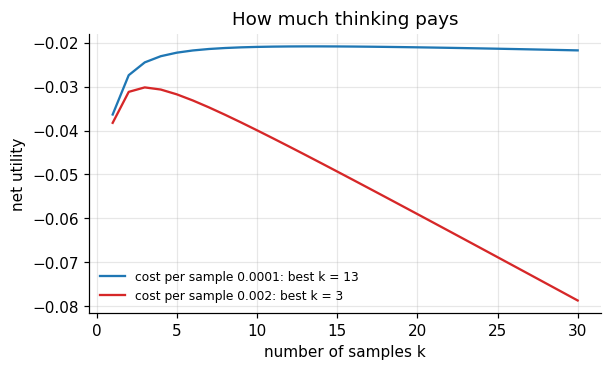

In [7]:
var_post = post_j @ (s_grid - post_j @ s_grid) ** 2     # scalar posterior variance
ks = np.arange(1, 31)                                   # (k,) number of samples

# Check the error formula by simulation
k_test, reps = 4, 100_000
truth = rng.choice(s_grid, size=reps, p=post_j)         # (reps,) the duration, drawn from the belief
est = rng.choice(s_grid, size=(reps, k_test), p=post_j).mean(axis=1)   # (reps,) k-sample estimate
print(f"posterior variance {var_post:.4f}; error with k={k_test}: "
      f"formula {var_post * (1 + 1 / k_test):.4f}, simulation {np.mean((est - truth) ** 2):.4f}")

fig, ax = plt.subplots(figsize=(6, 3.3))
for c, col in [(1e-4, "C0"), (2e-3, "C3")]:
    U = -var_post * (1 + 1 / ks) - c * ks               # (k,) net utility
    ax.plot(ks, U, color=col, label=f"cost per sample {c:g}: best k = {ks[U.argmax()]}")
ax.set(xlabel="number of samples k", ylabel="net utility", title="How much thinking pays")
ax.legend(frameon=False, fontsize=8)
plt.show()

### What Part I gives us

- A belief is a vector; Bayes' rule is three lines of array code.
- An action needs a utility; the optimal action maximizes expected utility under the belief.
- The loss picks the reported point: mean, median, mode, or a quantile.
- Exact inference explodes with the number of variables; approximations are not optional.
- A cost on computation changes what "optimal" means.

# Part II · Case study: which loss does a timer minimize?

## Stage 1 · Cognitive phenomenon

When people reproduce durations, their reports drift toward the middle of the range they have
been shown: short intervals come out too long, long ones too short (Hollingworth, 1910;
Jazayeri & Shadlen, 2010). Part I showed that a reported number is a belief *plus* a goal.
So the phenomenon has two possible sources, and we want to know how much each contributes.

The question for this case: **when people reproduce a duration, which summary of their belief do
they report, and do they change it when the payoffs change?** In pointing tasks people adjust
their aim to asymmetric penalties close to optimally (Trommershäuser, Maloney & Landy, 2003), and
the shape of the loss they minimize can be measured (Körding & Wolpert, 2004). We ask the same of
timing.

## Stage 2 · Behavioral experiment

Each trial shows one of seven durations from 0.4 to 1.6 s, then the participant holds a key to
reproduce it. Two blocks differ only in the feedback:

- **symmetric block**: points lost in proportion to squared error;
- **asymmetric block**: points lost in proportion to the error, three times as much for late
  presses as for early ones.

The design logic: the stimuli and the prior are identical, so any difference between blocks must
come from the loss.

We simulate a participant who is exactly optimal: mean in the symmetric block, the 0.25 quantile in
the asymmetric block. The participant also has motor noise $\sigma_\text{mot}$: the hand does not
release the key exactly when intended. An optimal agent should take that into account too. With
asymmetric costs, the quantile is taken of the belief *convolved with its own motor noise*.

In [8]:
durs = np.round(np.linspace(0.4, 1.6, 7), 2)            # (D,) the presented durations
n_per = 60                                              # trials per duration per block
ds = s_grid[1] - s_grid[0]


def posterior(sw):
    # p(s | m) for every m on the grid, as rows: (M, K)
    L = norm.pdf(np.log(m_grid)[:, None], np.log(s_grid)[None, :], sw)
    P = L * prior[None, :]
    return P / P.sum(axis=1, keepdims=True)


def readout(P, rule, s_mot=0.0, q=0.25):
    # Map each measurement to an intended action: (M,)
    if rule == "mean":
        return P @ s_grid
    if rule == "mode":
        return s_grid[P.argmax(axis=1)]
    if s_mot > 0:                                       # belief about the outcome includes motor noise
        P = gaussian_filter1d(P, s_mot / ds, axis=1, mode="constant")
        P = P / P.sum(axis=1, keepdims=True)
    level = {"median": 0.5, "quantile": q}[rule]
    idx = (P.cumsum(axis=1) < level).sum(axis=1)
    return s_grid[np.minimum(idx, K - 1)]


def simulate(rule, sw, s_mot, q=0.25, n=n_per):
    a_of_m = readout(posterior(sw), rule, s_mot, q)    # (M,)
    s = np.repeat(durs, n)                              # (N,) true durations
    m = s * np.exp(rng.normal(0, sw, s.size))           # (N,) measurements
    r = np.interp(m, m_grid, a_of_m) + rng.normal(0, s_mot, s.size)   # (N,) key presses
    return s, r


true_sw, true_mot = 0.15, 0.05
s_sym, r_sym = simulate("mean", true_sw, true_mot)
s_asy, r_asy = simulate("quantile", true_sw, true_mot, q=0.25)
print("symmetric block:", s_sym.shape, " asymmetric block:", s_asy.shape)

symmetric block: (420,)  asymmetric block: (420,)


## Stage 3 · Empirical signature

Before any model, describe the data. Two numbers per duration: the mean reproduction in each block,
and the difference between the blocks.

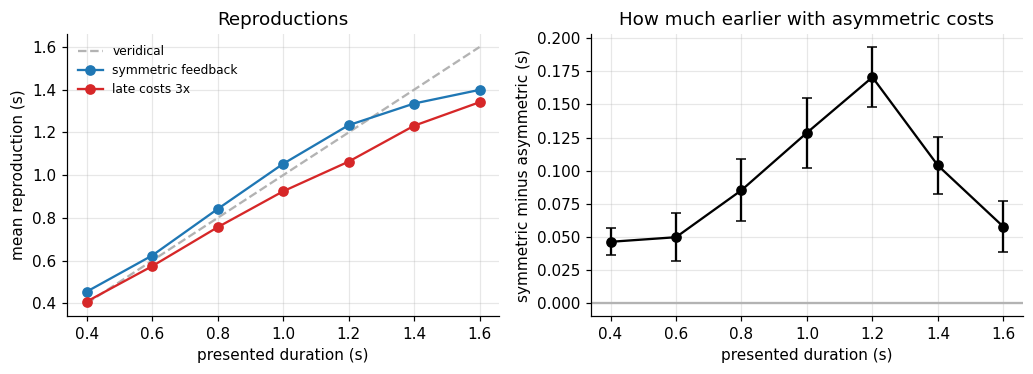

slope of reproduction on duration (symmetric): 0.83
shift per duration (s): [0.046 0.05  0.085 0.129 0.17  0.104 0.058]
slope of shift on duration: 0.048 +/- 0.015 s per s


In [9]:
mean_sym = np.array([r_sym[s_sym == d].mean() for d in durs])      # (D,)
mean_asy = np.array([r_asy[s_asy == d].mean() for d in durs])      # (D,)
shift = mean_sym - mean_asy                                         # (D,) how much earlier
se_shift = np.array([np.sqrt(r_sym[s_sym == d].var() / n_per + r_asy[s_asy == d].var() / n_per)
                     for d in durs])

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5))
axes[0].plot(durs, durs, color="0.7", ls="--", label="veridical")
axes[0].plot(durs, mean_sym, "o-", color="C0", label="symmetric feedback")
axes[0].plot(durs, mean_asy, "o-", color="C3", label="late costs 3x")
axes[0].set(xlabel="presented duration (s)", ylabel="mean reproduction (s)", title="Reproductions")
axes[0].legend(frameon=False, fontsize=8)
axes[1].errorbar(durs, shift, yerr=se_shift, fmt="o-", color="k", capsize=3)
axes[1].axhline(0, color="0.7")
axes[1].set(xlabel="presented duration (s)", ylabel="symmetric minus asymmetric (s)",
            title="How much earlier with asymmetric costs")
plt.tight_layout()
plt.show()
slope_sym = np.polyfit(durs, mean_sym, 1)[0]
print(f"slope of reproduction on duration (symmetric): {slope_sym:.2f}")
(b, b0), cov = np.polyfit(durs, shift, 1, w=1 / se_shift, cov="unscaled")
print("shift per duration (s):", shift.round(3))
print(f"slope of shift on duration: {b:.3f} +/- {np.sqrt(cov[0, 0]):.3f} s per s")

Three facts describe the data:

1. In both blocks the slope is below 1: central tendency.
2. Asymmetric costs move every reproduction earlier.
3. The shift is **not constant**. It grows with duration: the fitted slope is about three
   standard errors above zero. It may also fall at the very top, but that rests on one or two points.

The third fact is the useful one. A participant who simply "presses a bit earlier" would produce a
flat line. Any model has to explain why longer durations move more.

## Stage 4 · Computational model

The model is Part I applied to the task. Three steps per trial, each with a free or fixed
quantity:

| step | formula | meaning | parameter |
|---|---|---|---|
| measure | $\log m = \log s + \varepsilon$ | noisy sense of duration | $\sigma_w$, free |
| infer | $p(s \mid m) \propto p(m \mid s)\,p(s)$ | belief after one trial | none: the prior is the experiment's range |
| act | $a = $ mean, median, mode, or quantile of the belief | the loss being minimized | the rule |
| execute | $r = a + \eta,\; \eta \sim \mathcal N(0, \sigma_\text{mot}^2)$ | imprecise release | $\sigma_\text{mot}$, free |

The likelihood of one reproduction sums over the measurements the participant might have had:

$$p(r \mid s) = \sum_m p(m \mid s)\;\mathcal N\big(r;\, a(m),\, \sigma_\text{mot}^2\big).$$

In code: `W` has shape (N, M), the action table `a_of_m` has shape (M,), and the sum is a row sum.

The shift in Stage 3 now has an explanation. The quantile sits further below the mean when the
belief is wide, and log noise makes the belief wider for longer durations. The model also predicts
the fall at the top: near 1.6 s the prior edge cuts the belief off and narrows it, so the shift
should level off or drop there.

In [10]:
def neg_log_lik(theta, s, r, rule, q=0.25):
    sw, s_mot = np.exp(theta)                           # fit on log scale to keep both positive
    a_of_m = readout(posterior(sw), rule, s_mot if rule == "quantile" else 0.0, q)   # (M,)
    W = norm.pdf(np.log(m_grid)[None, :], np.log(s)[:, None], sw)
    W /= W.sum(axis=1, keepdims=True)                   # (N, M) p(m | s) for each trial
    like = (W * norm.pdf(r[:, None], a_of_m[None, :], s_mot)).sum(axis=1)   # (N,)
    return -np.log(like + 1e-300).sum()


def fit(s, r, rule, q=0.25):
    res = minimize(neg_log_lik, np.log([0.1, 0.1]), args=(s, r, rule, q), method="Nelder-Mead",
                   options={"xatol": 1e-3, "fatol": 1e-3})
    return np.exp(res.x), res.fun


for rule in ["mean", "median", "mode"]:
    (sw_hat, mot_hat), nll = fit(s_sym, r_sym, rule)
    print(f"{rule:6s}  sigma_w = {sw_hat:.3f}  sigma_mot = {mot_hat:.3f}   -log L = {nll:7.1f}")
print(f"truth   sigma_w = {true_sw:.3f}  sigma_mot = {true_mot:.3f}   (rule: mean)")

mean    sigma_w = 0.154  sigma_mot = 0.043   -log L =  -351.7


median  sigma_w = 0.173  sigma_mot = 0.038   -log L =  -344.5


mode    sigma_w = 0.125  sigma_mot = 0.070   -log L =  -265.3
truth   sigma_w = 0.150  sigma_mot = 0.050   (rule: mean)


The mean observer fits best and recovers both noise parameters. But look at the median observer:
its fit is close, and it pays for the wrong rule by moving its noise parameters. The mode observer
is clearly worse. One data set is not enough to trust this ranking, so we run the standard check.

**Model recovery.** Simulate many data sets from each rule, fit all three rules to each, and count
how often the generating rule wins.

[[0.83 0.17 0.  ]
 [0.17 0.83 0.  ]
 [0.   0.   1.  ]]


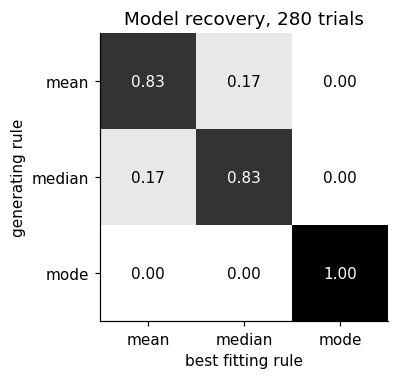

In [11]:
rules = ["mean", "median", "mode"]
n_rep = 6
confusion = np.zeros((3, 3))                            # rows: generating rule, columns: winning rule
for g, gen in enumerate(rules):
    for _ in range(n_rep):
        s_g, r_g = simulate(gen, true_sw, true_mot)
        nlls = [fit(s_g, r_g, rule)[1] for rule in rules]
        confusion[g, int(np.argmin(nlls))] += 1
confusion /= n_rep
print(confusion.round(2))

fig, ax = plt.subplots(figsize=(4.2, 3.4))
im = ax.imshow(confusion, cmap="Greys", vmin=0, vmax=1)
for i in range(3):
    for k in range(3):
        ax.text(k, i, f"{confusion[i, k]:.2f}", ha="center", va="center",
                color="w" if confusion[i, k] > 0.5 else "k")
ax.set(xticks=range(3), xticklabels=rules, yticks=range(3), yticklabels=rules,
       xlabel="best fitting rule", ylabel="generating rule", title="Model recovery, 280 trials")
ax.grid(False)
plt.show()

The mode is identified every time. Mean and median are confused in one data set out of six, even
though the simulated participants differ in nothing but the rule. Their predictions differ only
where the belief is lopsided, and there by less than the trial to trial noise.

**This is the failure case of the symmetric block.** It cannot reliably tell us whether the timer
minimizes squared or absolute error. Here the simulated participant is perfectly stationary and has
no lapses; real data would blur the small difference further. More trials of the same kind buy
little, because the two rules only disagree on the few trials where the belief hits the prior edge.
A better design makes the candidate losses disagree strongly. The asymmetric block does that for a
different question: not mean versus median, but whether a changed loss is used at all.

### A prediction with no free parameters

Fit $\sigma_w$ and $\sigma_\text{mot}$ on the symmetric block only. Then decision theory fixes the
asymmetric block completely: the quantile is $q = 1/(1+3) = 0.25$, taken of the belief convolved with
the fitted motor noise. Nothing is refitted.

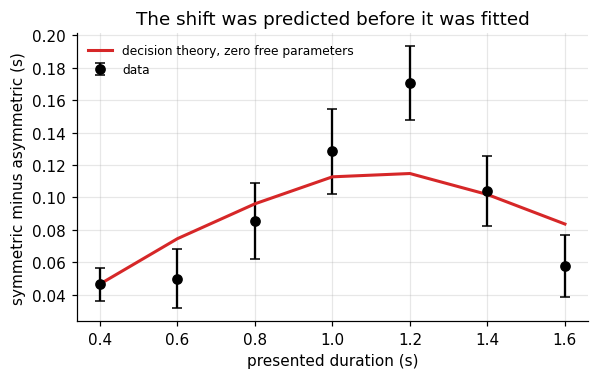

predicted shift: [0.047 0.075 0.096 0.113 0.115 0.102 0.084]


In [12]:
(sw_hat, mot_hat), _ = fit(s_sym, r_sym, "mean")
a_mean = readout(posterior(sw_hat), "mean")             # (M,)
a_q = readout(posterior(sw_hat), "quantile", mot_hat, q=0.25)   # (M,)


def predicted_means(a_of_m, sw):
    W = norm.pdf(np.log(m_grid)[None, :], np.log(durs)[:, None], sw)
    W /= W.sum(axis=1, keepdims=True)                   # (D, M)
    return W @ a_of_m                                   # (D,) expected reproduction per duration


pred_shift = predicted_means(a_mean, sw_hat) - predicted_means(a_q, sw_hat)   # (D,)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.errorbar(durs, shift, yerr=se_shift, fmt="o", color="k", capsize=3, label="data")
ax.plot(durs, pred_shift, color="C3", lw=2, label="decision theory, zero free parameters")
ax.set(xlabel="presented duration (s)", ylabel="symmetric minus asymmetric (s)",
       title="The shift was predicted before it was fitted")
ax.legend(frameon=False, fontsize=8)
plt.show()
print("predicted shift:", pred_shift.round(3))

The predicted curve follows the data without having seen the asymmetric block. No point misses it
by more than about two standard errors; the largest miss is at 1.2 s. The curve also bends down at
the top, as Stage 4 said it would.

### Three levels of claim

Keep them apart. So far we have only the first.

| claim | what supports it | what we have here |
|---|---|---|
| **consistent with** | the model reproduces the data pattern | yes, including a parameter free prediction |
| **implementable** | a plausible circuit can compute it | Stage 5 |
| **causal** | changing the mechanism changes behavior as predicted | not addressed by behavior alone |

## Stage 5 · Neural implementation

Can neurons compute a quantile? Reading out a mean needs a weighted sum. A quantile needs something
else: a running total of belief, compared with a threshold. Reproduction tasks offer a natural
circuit for that.

- A population of duration tuned neurons responds to the flash. Their spike counts $\mathbf n$
  define a log posterior, as in Foundations 9:
  $\log p(s \mid \mathbf n) = \sum_i n_i \log f_i(s) - \sum_i f_i(s) + \log p(s) + \text{const}$.
- During the reproduction, elapsed time $t$ grows. A downstream unit accumulates the belief mass
  for durations shorter than $t$: $C(t) = \sum_{s \le t} p(s \mid \mathbf n)$.
- The key is released when $C(t)$ crosses a threshold $\theta$.

With $\theta = 0.5$ the circuit releases at the median; with $\theta = 0.25$ at the 0.25 quantile.
Changing the payoff only needs to change one number, the threshold.

spikes per trial: 3.2; width of decoded belief: 0.181 log units (behavioral sigma_w 0.15)


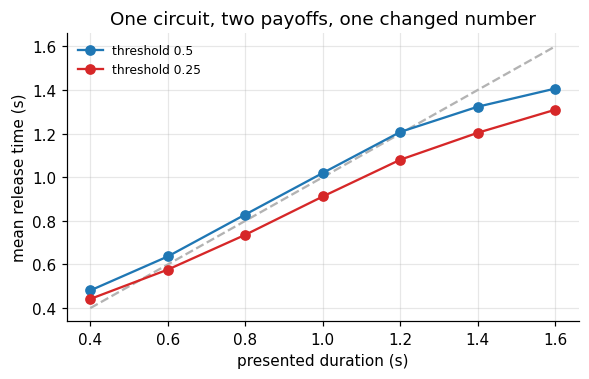

neural shift (theta 0.5 minus 0.25): [0.039 0.06  0.093 0.108 0.127 0.119 0.097]


In [13]:
n_neur = 40
pref = np.exp(np.linspace(np.log(0.25), np.log(2.5), n_neur))       # (I,) preferred durations
width, gain = 0.25, 0.3                                              # tuning width (log units), expected peak count

f = gain * np.exp(-0.5 * ((np.log(s_grid)[:, None] - np.log(pref)[None, :]) / width) ** 2)   # (K, I)
log_f = np.log(f + 1e-12)


def neural_release(s_true, theta, n_trials=400):
    counts = rng.poisson(gain * np.exp(-0.5 * ((np.log(s_true) - np.log(pref)) / width) ** 2),
                         size=(n_trials, n_neur))                    # (T, I) spike counts
    log_post = counts @ log_f.T - f.sum(axis=1) + np.log(prior + 1e-300)   # (T, K)
    p = np.exp(log_post - log_post.max(axis=1, keepdims=True))
    p /= p.sum(axis=1, keepdims=True)                                # (T, K) belief per trial
    C = p.cumsum(axis=1)                                             # (T, K) accumulated belief as t grows
    return s_grid[(C < theta).sum(axis=1)]                           # (T,) release times


# How wide is the decoded belief? Compare with the behavioral Weber fraction.
cnt = rng.poisson(gain * np.exp(-0.5 * ((np.log(1.0) - np.log(pref)) / width) ** 2), size=(2000, n_neur))
lp = cnt @ log_f.T - f.sum(axis=1)                                   # flat prior: width from the code alone
pp = np.exp(lp - lp.max(axis=1, keepdims=True)); pp /= pp.sum(axis=1, keepdims=True)
mu = pp @ np.log(s_grid)
sd_log = np.sqrt((pp * (np.log(s_grid)[None, :] - mu[:, None]) ** 2).sum(axis=1)).mean()
print(f"spikes per trial: {cnt.sum(axis=1).mean():.1f}; width of decoded belief: {sd_log:.3f} log units "
      f"(behavioral sigma_w {true_sw})")


fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(durs, durs, color="0.7", ls="--")
rel = {}
for theta, col in [(0.5, "C0"), (0.25, "C3")]:
    rel[theta] = np.array([neural_release(d, theta).mean() for d in durs])
    ax.plot(durs, rel[theta], "o-", color=col, label=f"threshold {theta}")
ax.set(xlabel="presented duration (s)", ylabel="mean release time (s)",
       title="One circuit, two payoffs, one changed number")
ax.legend(frameon=False, fontsize=8)
plt.show()
print("neural shift (theta 0.5 minus 0.25):", (rel[0.5] - rel[0.25]).round(3))

The gain was chosen so that the population fires only a few spikes per trial, which makes the
decoded belief about as wide as the behavioral Weber fraction. With that one calibration the
circuit reproduces the ideal observer's shift: growing with duration, bending down at the prior
edge. With more spikes the belief narrows and the shift shrinks. That is a second, independent
prediction: a participant whose timing is more precise should show a smaller payoff shift.

This establishes only that the computation is **implementable**. Ramping activity that reaches a
threshold at the moment of a timed response is a well known pattern in timing tasks, but the
simulation does not show that any brain area does this. A causal claim would need an intervention:
for example, a manipulation that changes the threshold and moves reproductions by the amount the
model predicts, without changing their variability.

## Stage 6 · Prediction and failure

The model makes claims that could be false. Each one names the result that would reject it.

| prediction | how to test | rejected if |
|---|---|---|
| The shift follows the width of the belief: it grows with duration and levels off at the prior edge. | asymmetric vs symmetric blocks, several durations | the shift is flat (a fixed "press earlier" rule) |
| The quantile follows the cost ratio, $q = c_\text{early} / (c_\text{early} + c_\text{late})$. | blocks with ratios 1:3, 1:1, 3:1 | shifts do not order with $q$, or saturate early |
| Noisier timers shift more. | individual differences in $\sigma_w$ from the symmetric block | shift size is unrelated to fitted $\sigma_w$ |
| Mean and median are not separable in this design. | model recovery before running the study | (a design property, not a hypothesis) |

Below we test the first row against its natural rival: a participant who has learned a constant
offset $\delta$, $a = \text{mean} - \delta$. The rival gets one free parameter, fitted on half of the
asymmetric trials. Both models are scored on the other half.

fitted offset delta = 0.070 s
held out -log L: quantile model -159.2, constant offset -151.0
difference 8.3 in favor of the quantile model


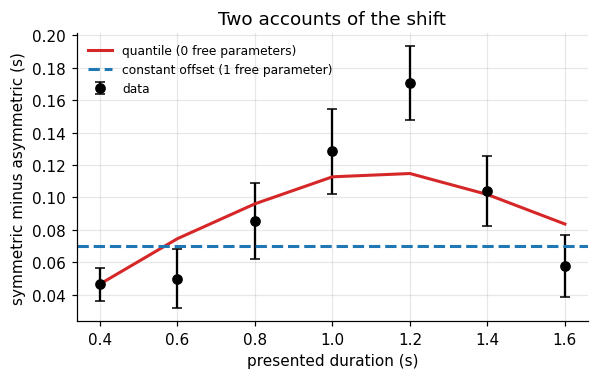

In [14]:
half = rng.permutation(s_asy.size)
train, test = half[: s_asy.size // 2], half[s_asy.size // 2:]


def nll_actions(a_of_m, s, r, sw, s_mot):
    W = norm.pdf(np.log(m_grid)[None, :], np.log(s)[:, None], sw)
    W /= W.sum(axis=1, keepdims=True)                   # (N, M)
    return -np.log((W * norm.pdf(r[:, None], a_of_m[None, :], s_mot)).sum(axis=1) + 1e-300).sum()


# Rival: constant offset, delta fitted on the training half
deltas = np.linspace(0, 0.3, 61)
train_nll = [nll_actions(a_mean - d, s_asy[train], r_asy[train], sw_hat, mot_hat) for d in deltas]
delta_hat = deltas[int(np.argmin(train_nll))]

test_quant = nll_actions(a_q, s_asy[test], r_asy[test], sw_hat, mot_hat)
test_offset = nll_actions(a_mean - delta_hat, s_asy[test], r_asy[test], sw_hat, mot_hat)
print(f"fitted offset delta = {delta_hat:.3f} s")
print(f"held out -log L: quantile model {test_quant:.1f}, constant offset {test_offset:.1f}")
print(f"difference {test_offset - test_quant:.1f} in favor of the "
      f"{'quantile' if test_quant < test_offset else 'offset'} model")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.errorbar(durs, shift, yerr=se_shift, fmt="o", color="k", capsize=3, label="data")
ax.plot(durs, pred_shift, color="C3", lw=2, label="quantile (0 free parameters)")
ax.axhline(delta_hat, color="C0", lw=2, ls="--", label="constant offset (1 free parameter)")
ax.set(xlabel="presented duration (s)", ylabel="symmetric minus asymmetric (s)", title="Two accounts of the shift")
ax.legend(frameon=False, fontsize=8)
plt.show()

Here the quantile model wins on held out trials, with one parameter fewer. That is the expected
outcome, because the data were generated by it. What makes the test worth running on real people
is that it can fail. Three ways it could:

- **A flat shift.** Participants may learn a simple offset from the feedback instead of reading
  their belief at a new point. Then the rival wins, and decision theory describes the goal but not
  the computation.
- **Under-adjustment.** Participants may move in the right direction but not far enough. Then $q$
  must be fitted rather than derived, and the zero parameter prediction is lost.
- **The wrong noise model.** The shape of the shift depends on log noise and on the prior edge. If the noise in
  real timing is not proportional to duration, the predicted shape changes. Unit 13 examines
  exactly that.

## What to carry forward

- State the goal before the mechanism. The same belief gives different reports under different
  losses.
- Bayes on a grid: `joint = lik * prior[:, None]`, `post = joint / joint.sum(0)`. Shapes first.
- Squared loss reports the mean, absolute loss the median, all or none the mode, asymmetric linear
  loss a quantile set by the cost ratio.
- Exact inference grows as $K^N$. Approximation is the normal case, and computation has a price.
- Check identifiability before collecting data. Here mean and median were nearly inseparable.
- The best test is a prediction fixed in advance: changing only the payoff should move responses
  by an amount set by the width of the belief.

## References

- de Finetti, B. (1937). La prévision: ses lois logiques, ses sources subjectives. *Annales de
  l'Institut Henri Poincaré*, 7(1), 1 to 68.
- Gibbon, J. (1977). Scalar expectancy theory and Weber's law in animal timing. *Psychological
  Review*, 84(3), 279 to 325.
- Hollingworth, H. L. (1910). The central tendency of judgment. *Journal of Philosophy, Psychology
  and Scientific Methods*, 7(17), 461 to 469.
- Jazayeri, M., & Shadlen, M. N. (2010). Temporal context calibrates interval timing. *Nature
  Neuroscience*, 13(8), 1020 to 1026.
- Körding, K. P., & Wolpert, D. M. (2004). The loss function of sensorimotor learning. *Proceedings
  of the National Academy of Sciences*, 101(26), 9839 to 9842.
- Lieder, F., & Griffiths, T. L. (2020). Resource-rational analysis: Understanding human cognition
  as the optimal use of limited computational resources. *Behavioral and Brain Sciences*, 43, e1.
- Marr, D. (1982). *Vision*. W. H. Freeman.
- Trommershäuser, J., Maloney, L. T., & Landy, M. S. (2003). Statistical decision theory and the
  selection of rapid, goal-directed movements. *Journal of the Optical Society of America A*,
  20(7), 1419 to 1433.
- Vul, E., Goodman, N., Griffiths, T. L., & Tenenbaum, J. B. (2014). One and done? Optimal decisions
  from very few samples. *Cognitive Science*, 38(4), 599 to 637.
- Wald, A. (1950). *Statistical Decision Functions*. Wiley.